Análisis Exploratorio de Datos (EDA) de Accidentes de Tránsito en Barranquilla

In [31]:
import importlib
import src.eda

importlib.reload(src.eda)

from src.eda import AnalisisExploratorio

eda = AnalisisExploratorio(
    "../dataset/dataset_limpio_eda.csv"
)

eda.cargar_datos()

Dataset cargado correctamente.


,FECHA,ACCIDENTES,GRAVEDAD_ACCIDENTE,CLASE_ACCIDENTE,PRECIPITACION_MM,LLUVIA,COMPARENDOS,COD_INFRACCION,TIPO_INFRACCION,CLASE_VEHICULO_INFRACTOR,SERVICIO_VEHICULO_INFRACTOR,PRECIPITACION_FALTANTE
0,2018-01-01,7.0,Solo daños,Choque,0.0,No,293.0,C29,TRÁNSITO,AUTOMOVIL,PARTICULAR,0
1,2018-01-02,11.0,Solo daños,Choque,0.0,No,347.0,C02,TRÁNSITO,AUTOMOVIL,PARTICULAR,0
2,2018-01-03,12.0,Solo daños,Choque,0.0,No,269.0,C02,TRÁNSITO,AUTOMOVIL,PARTICULAR,0
3,2018-01-04,16.0,Solo daños,Choque,4.5,Sí,253.0,C02,TRÁNSITO,AUTOMOVIL,PARTICULAR,0
4,2018-01-05,12.0,Solo daños,Choque,0.0,No,317.0,C02,TRÁNSITO,AUTOMOVIL,PARTICULAR,0
...,...,...,...,...,...,...,...,...,...,...,...,...
3042,2026-06-12,2.0,Con heridos,Choque,0.0,Sin dato,182.0,C02,TRÁNSITO,AUTOMOVIL,PARTICULAR,1
3043,2026-06-13,1.0,Con heridos,Choque,0.0,Sin dato,165.0,C02,TRÁNSITO,AUTOMOVIL,PARTICULAR,1
3044,2026-06-14,1.0,Con muertos,Choque,0.0,Sin dato,76.0,C29,TRÁNSITO,AUTOMOVIL,PARTICULAR,1
3045,2026-06-15,3.0,Con heridos,Choque,0.0,Sin dato,75.0,C29,TRÁNSITO,AUTOMOVIL,PARTICULAR,1


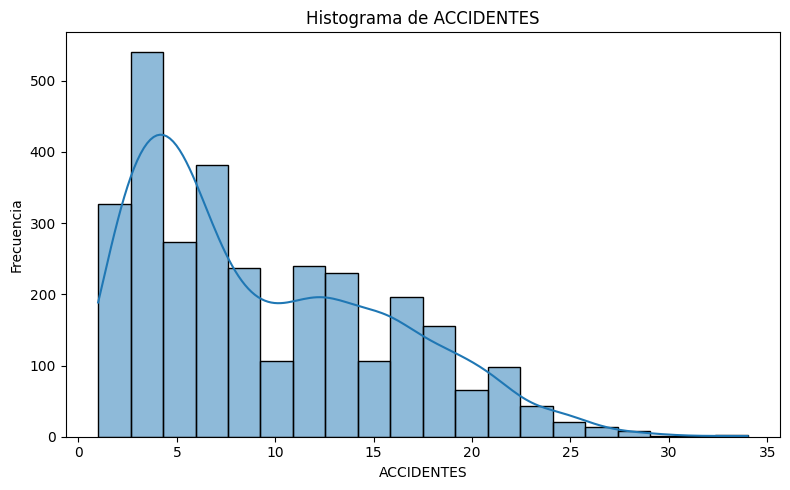

In [32]:
eda.graficar_histograma("ACCIDENTES")

**Interpretación:** El número de accidentes diarios presenta variabilidad durante el periodo analizado. Se registró un promedio de 9,36 accidentes por día, con valores entre 1 y 34. Esto muestra que la cantidad de accidentes no fue constante y que hubo días con cifras considerablemente superiores al promedio.

In [35]:
eda.df["ACCIDENTES"].describe()
print(eda.df["ACCIDENTES"].value_counts().sort_index())

ACCIDENTES
1.0     111
2.0     216
3.0     259
4.0     282
5.0     274
6.0     224
7.0     157
8.0     130
9.0     107
10.0    106
11.0    114
12.0    126
13.0    126
14.0    104
15.0    106
16.0    119
17.0     77
18.0     85
19.0     71
20.0     65
21.0     58
22.0     40
23.0     16
24.0     27
25.0     21
26.0     10
27.0      4
28.0      5
29.0      3
30.0      1
31.0      1
33.0      1
34.0      1
Name: count, dtype: int64


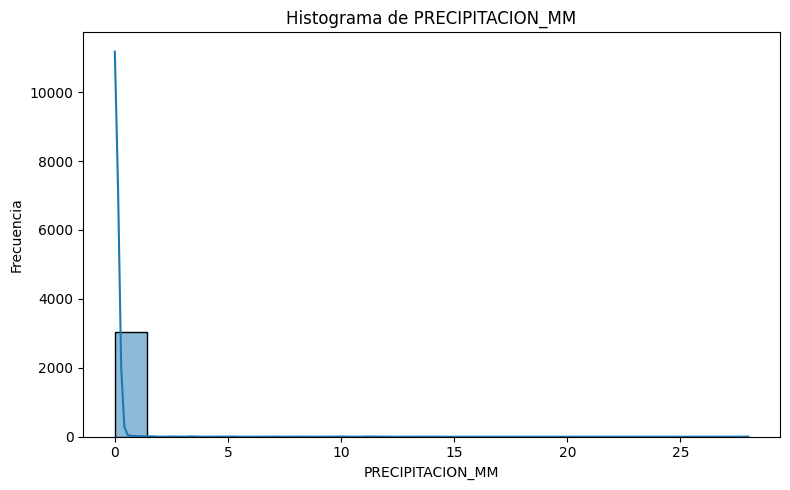

In [33]:
eda.graficar_histograma("PRECIPITACION_MM")

**Interpretación:** La precipitación presenta una distribución concentrada en valores de cero, mientras que unos pocos registros alcanzan valores elevados, con un máximo de 28 mm. Esta distribución está sesgada hacia la derecha. Por ello, conviene analizar los días lluviosos por separado y tener en cuenta que los registros sin dato no deben interpretarse como días sin lluvia.

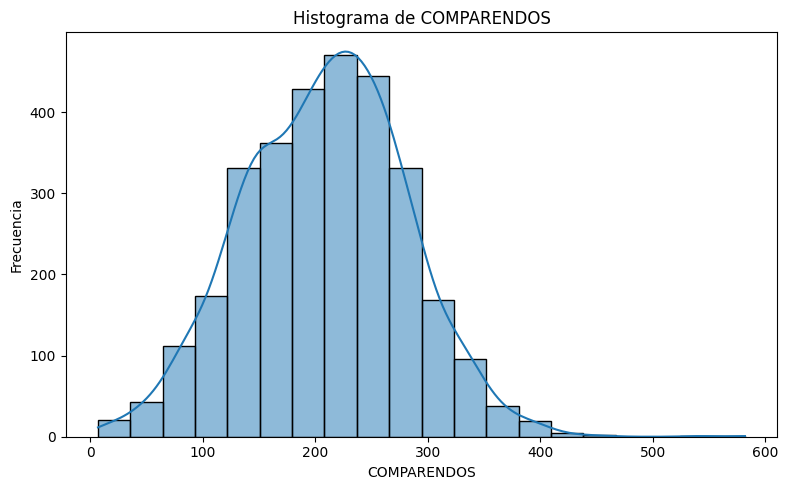

In [34]:
eda.graficar_histograma("COMPARENDOS")

**Interpretación:** La cantidad diaria de comparendos presenta variabilidad, con un promedio de 208,90 registros y valores entre 7 y 582. Los valores elevados podrían corresponder a jornadas con mayor actividad de control o a otras condiciones del registro. Se necesitaría información adicional para identificar sus causas.

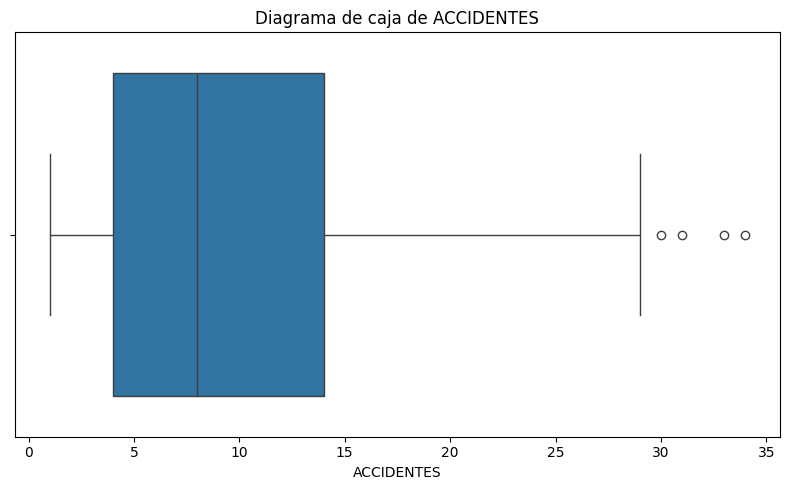

In [38]:
eda.graficar_boxplot("ACCIDENTES")

**Interpretación**: El diagrama de caja muestra que la mediana es de 8 accidentes por día. El 50 % central de los registros se encuentra entre 4 y 14 accidentes. Se observa una mayor concentración de datos en valores bajos e intermedios, mientras que algunos días presentan cantidades considerablemente superiores. Según el criterio del rango intercuartílico, se identifican 4 posibles valores atípicos por encima del límite superior. Estos valores representan días con una cantidad de accidentes inusualmente alta y no necesariamente errores en los datos.

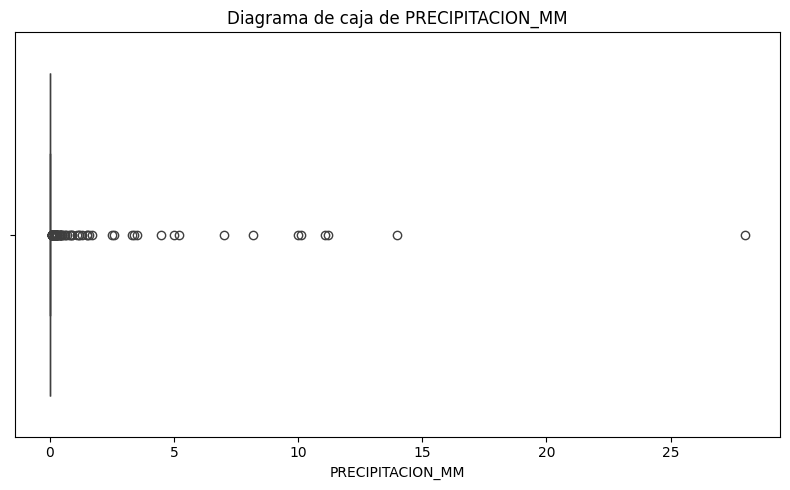

In [39]:
eda.graficar_boxplot("PRECIPITACION_MM")

**Interpretación**: El diagrama de caja presenta una concentración de valores en 0 mm de precipitación, por lo que la caja puede aparecer comprimida en ese punto. Sin embargo, se observan valores superiores que amplían el rango de los datos y pueden aparecer como posibles valores atípicos. Esto refleja una distribución asimétrica, con pocos registros de precipitación elevada. Es importante considerar la variable `PRECIPITACION_FALTANTE`, porque algunos valores registrados como cero podrían corresponder a datos de lluvia faltantes y no necesariamente a días sin precipitación.

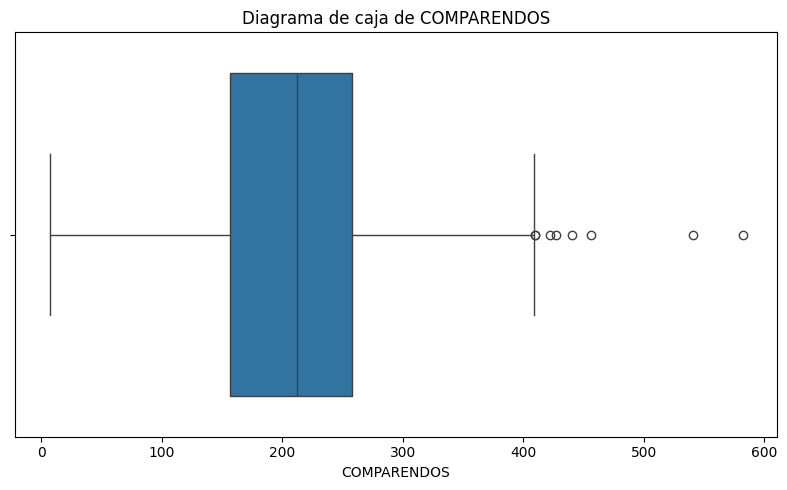

In [40]:
eda.graficar_boxplot("COMPARENDOS")

**Interpretación**: El diagrama de caja muestra una mediana de 212 comparendos. El 50 % central de los registros se encuentra entre 157 y 258 comparendos. También se presentan valores superiores al límite habitual de la distribución, que pueden identificarse como posibles valores atípicos. Estos registros indican días con una cantidad de comparendos considerablemente mayor que la observada en la mayoría de los días. Su presencia debe analizarse antes de descartarlos, ya que podrían corresponder a variaciones reales en los registros.

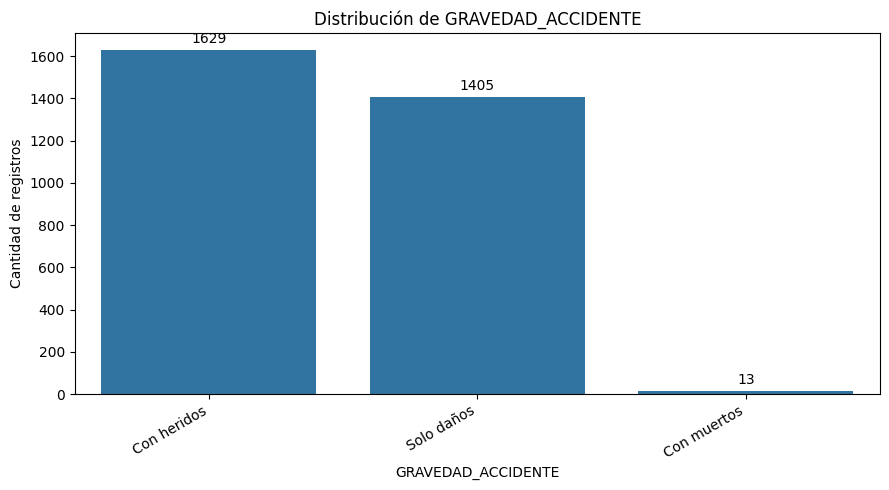

In [42]:
eda.graficar_categoria("GRAVEDAD_ACCIDENTE")

**Interpretación**: La categoría más frecuente es **“Con heridos”**, con 1.629 registros (53,46 %), seguida de **“Solo daños”**, con 1.405 registros (46,11 %). La categoría **“Con muertos”** presenta 13 registros (0,43 %). Estos resultados muestran que, en el conjunto analizado, predominan los accidentes que reportan personas heridas, seguidos de aquellos que ocasionan únicamente daños materiales. Los accidentes con víctimas mortales representan una proporción pequeña de los registros.

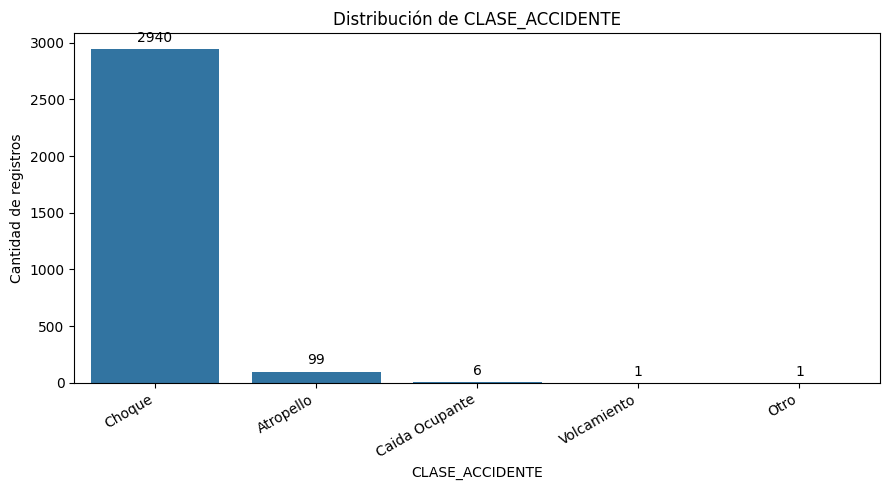

In [43]:
eda.graficar_categoria("CLASE_ACCIDENTE")

**Interpretación**: La categoría **“Choque”** predomina ampliamente, con 2.940 registros de los 3.047 analizados. Le siguen los atropellos, con 99 registros, mientras que la caída de ocupante, el volcamiento y la categoría “Otro” presentan frecuencias considerablemente menores. Esto evidencia que los choques son la clase de accidente más representada en el conjunto de datos. Debido a la diferencia entre frecuencias, las categorías menos comunes pueden resultar difíciles de distinguir en el gráfico.

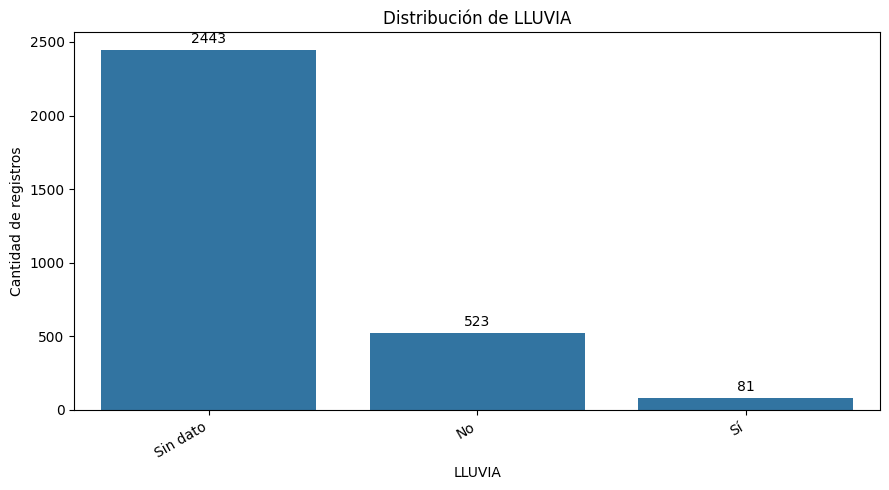

In [44]:
eda.graficar_categoria("LLUVIA")


**Interpretación**: La categoría “Sin dato” representa el 80,18 % de los registros, mientras que “No” corresponde al 17,16 % y “Sí” al 2,66 %. Por tanto, la mayoría de los registros no cuenta con una clasificación disponible sobre la presencia de lluvia. Esta limitación impide determinar, únicamente con este gráfico, si la lluvia es frecuente durante los accidentes analizados. Es necesario considerar la calidad y disponibilidad de los datos meteorológicos antes de establecer comparaciones.

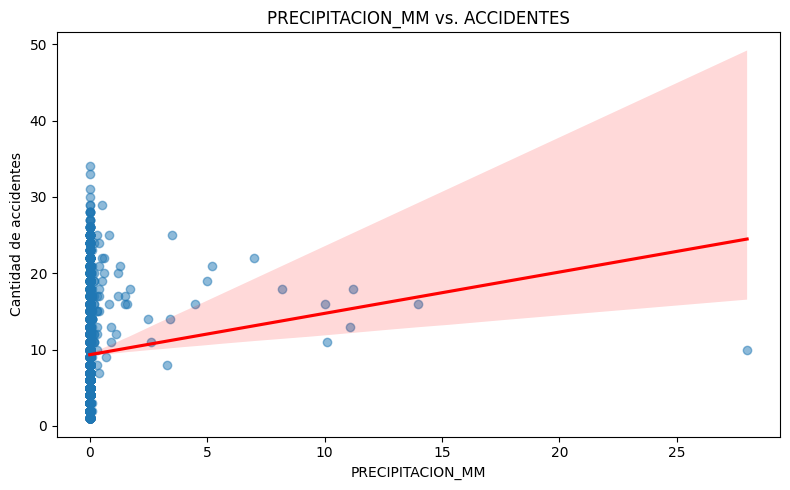

In [46]:
eda.graficar_relacion("PRECIPITACION_MM")

### Interpretación: Precipitación vs. accidentes

El diagrama de dispersión permite observar la relación entre la precipitación en milímetros y la cantidad de accidentes registrados. El coeficiente de correlación de Pearson es de **0,0634**, lo que indica una relación lineal positiva muy débil entre ambas variables. Esto significa que, en los datos analizados, no se observa una asociación lineal importante entre la precipitación y la cantidad de accidentes.

Además, los cuartiles de la precipitación son iguales a cero, lo que evidencia una alta concentración de registros en ese valor. La precipitación máxima registrada es de 28 mm, mientras que el promedio de accidentes es de aproximadamente 9,36 por registro. Por tanto, estos resultados no permiten concluir que la lluvia aumente o disminuya los accidentes; únicamente describen una relación lineal muy débil en el conjunto estudiado.

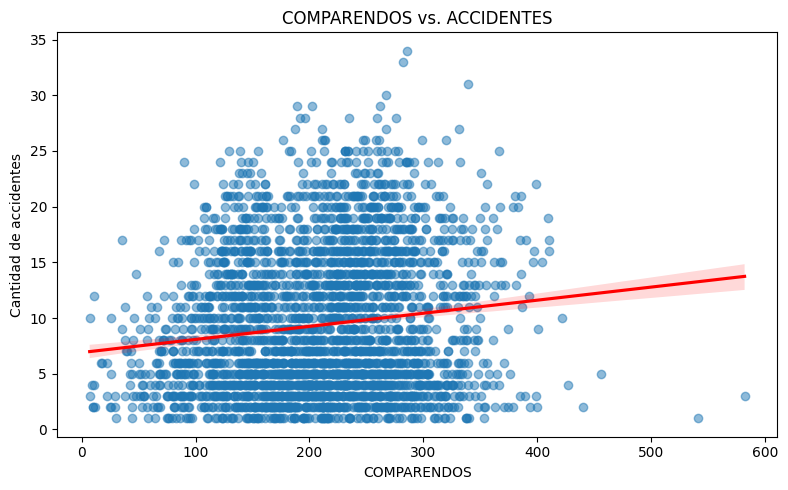

In [49]:
eda.graficar_relacion("COMPARENDOS")

### Interpretación: Comparendos vs. accidentes

El diagrama de dispersión permite analizar la relación entre la cantidad de comparendos y los accidentes registrados. La línea de tendencia presenta una inclinación positiva, coherente con el coeficiente de correlación de 0,1336, que indica una asociación lineal positiva débil. Esto significa que ambas variables tienden a aumentar conjuntamente, aunque la relación observada es poco marcada.

La cantidad de comparendos presenta un promedio de 208,90 registros, mientras que los accidentes tienen un promedio de 9,36. Sin embargo, esta asociación no demuestra que los comparendos causen accidentes, ya que pueden intervenir otros factores.

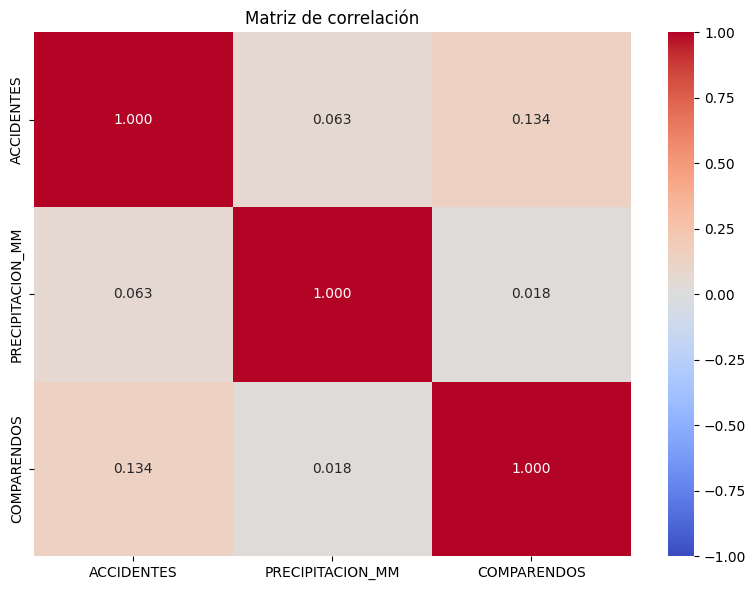

In [55]:
eda.graficar_matriz_correlacion()

### Interpretación de la matriz de correlación

La matriz de correlación muestra que las relaciones lineales entre las variables analizadas son débiles. La correlación entre accidentes y precipitación es de 0,063, mientras que entre accidentes y comparendos es de 0,134. Por su parte, la correlación entre precipitación y comparendos es de aproximadamente 0,018, lo que indica una relación lineal prácticamente nula. En conjunto, los resultados muestran que ninguna de las parejas de variables presenta una correlación lineal fuerte. Sin embargo, estos coeficientes no descartan otras relaciones ni permiten establecer causalidad.

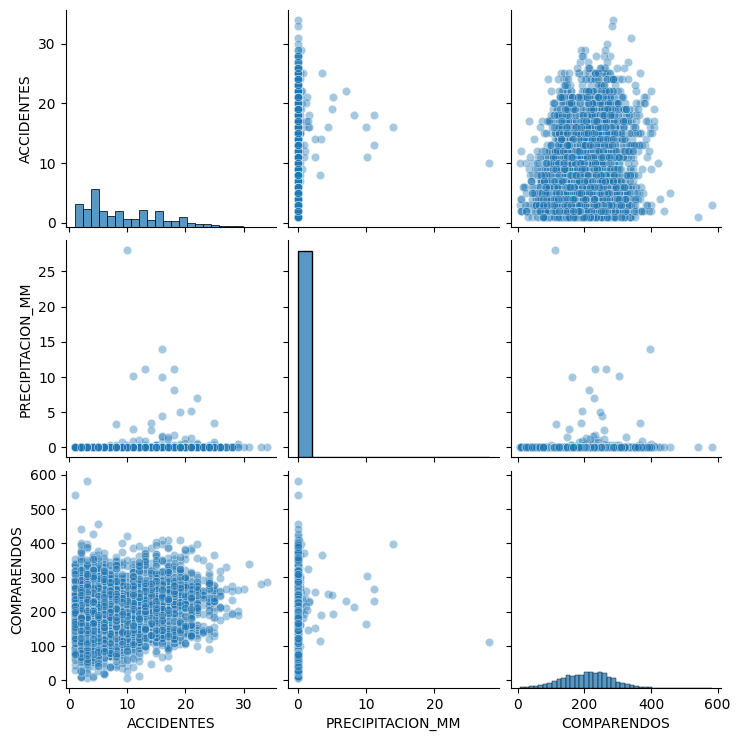

In [15]:
eda.graficar_matriz_dispersion()

### Interpretación de la matriz de dispersión

La matriz de dispersión permite observar las relaciones entre accidentes, precipitación y comparendos. La correlación entre accidentes y precipitación es de **0,063**, lo que indica una relación lineal positiva muy débil. Entre accidentes y comparendos, la correlación es de **0,134**, también positiva y débil. Finalmente, la correlación entre precipitación y comparendos es de **0,018**, lo que representa una relación lineal prácticamente nula.

En general, ninguna pareja de variables presenta una correlación lineal fuerte. Estos resultados permiten describir las relaciones presentes en los datos, pero no demuestran causalidad ni descartan posibles relaciones no lineales.